# 空间分析与用户行为

**本节课要做什么？**

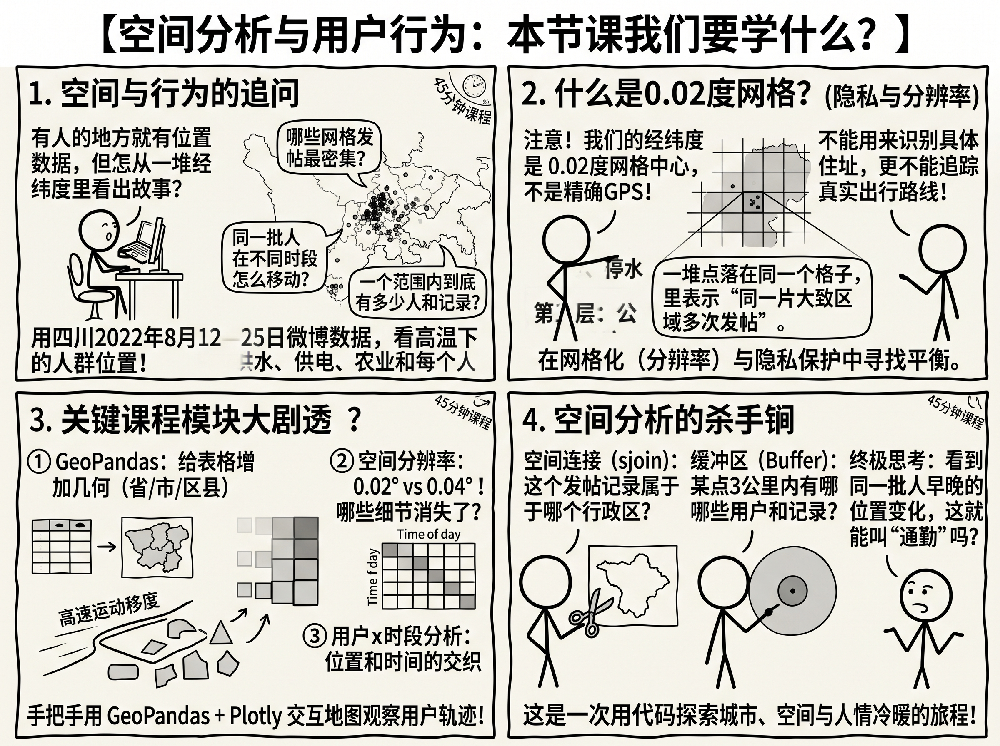

学习空间分析的基本知识，学习空间数据的处理、可视化，理解用户的空间行为。


<a id="course-toc"></a>
**目录**

- [1 从发帖位置提出问题](#section-1)
- [2 GeoPandas：为表格增加几何](#section-2)
  - [2.1 矢量与栅格：两种空间数据模型](#section-2-1)
  - [2.2 经纬度与米：先投影，再测量](#section-2-2)
  - [2.3 省、市、区县：行政边界怎样读取？](#section-2-3)
  - [2.4 成都区县：换一个行政层级](#section-2-4)
- [3 网格汇总：记录多与用户多是否一样？](#section-3)
  - [3.1 把网格画成面：空间分辨率](#section-3-1)
    - [3.1.1 同一组格子，改成栅格数组](#section-3-1-1)
  - [3.2 改成0.04度：哪些细节消失了？](#section-3-2)
  - [3.3 Plotly也可以更换高德底图](#section-3-3)
- [4 回到同一用户：位置和时段](#section-4)
  - [4.1 网格×时段表：每个时段分别归一化](#section-4-1)
- [5 空间连接：位置记录属于哪个范围？](#section-5)
  - [5.1 先选关系，再选保留哪些记录](#section-5-1)
  - [5.2 给成都位置记录连接区县，再汇总](#section-5-2)
    - [5.2.1 分级设色：把区县统计画回地图](#section-5-2-1)
  - [5.3 缓冲区与空间连接：3公里内有哪些记录？](#section-5-3)
  - [5.4 空间连接与几何叠置有什么不同？](#section-5-4)
- [6 综合练习与解释](#section-6)
  - [6.1 改变分析范围](#section-6-1)
  - [6.2 找出重复记录较多的网格](#section-6-2)
  - [6.3 开放问题：能称为通勤吗？](#section-6-3)

<a id="section-1"></a>
## 1 从发帖位置提出问题 **[重点]**

关注的问题：记录集中在哪些网格？同一用户在不同时段的位置分布是否一样？某个分析范围内有多少记录和用户？

本节用四川2022年8月12—25日的可用记录。经纬度是**0.02度网格中心**，不是精确GPS点。一个网格重复出现，表示多次记录落在同一粗位置；不能据此识别住址或实际出行路线。



In [ ]:
# 保持整个tutorials文件夹结构；支持从项目根目录或tutorials目录启动。
from pathlib import Path
TUTORIAL_DIR = Path('.') if Path('data/posts_two_weeks.parquet').is_file() else Path('tutorials')
DATA = TUTORIAL_DIR / 'data/posts_two_weeks.parquet'
assert DATA.is_file(), '请先完整解压课堂资料，并用VS Code打开包含tutorials的文件夹'

In [ ]:
# 在开始读表时导入Pandas；只取本节需要的字段。
import pandas as pd
columns = ['post_id', 'user_id', 'created_at', 'date', 'city_code', 'city',
           'longitude_grid', 'latitude_grid', 'coordinate_valid']
posts = pd.read_parquet(DATA, columns=columns,
                       filters=[('province_code', '==', '51'), ('usable_text', '==', True)])
# 统一北京时间，再取小时；不要把UTC小时与北京时间混用。
posts['created_at'] = pd.to_datetime(posts['created_at'], utc=True).dt.tz_convert('Asia/Shanghai')
posts['hour'] = posts['created_at'].dt.hour
print('记录数：', len(posts), '用户数：', posts['user_id'].nunique())
posts[['created_at', 'city', 'longitude_grid', 'latitude_grid']].head()

<a id="section-2"></a>
## 2 GeoPandas：为表格增加几何 **[重点]**

什么是`Geopandas`

Pandas的DataFrame保存普通字段；GeoPandas的GeoDataFrame增加`geometry`列和坐标参考系`crs`。点是位置，线连接顶点，面表示范围。这里先学点和面，不把离散微博点连成轨迹。



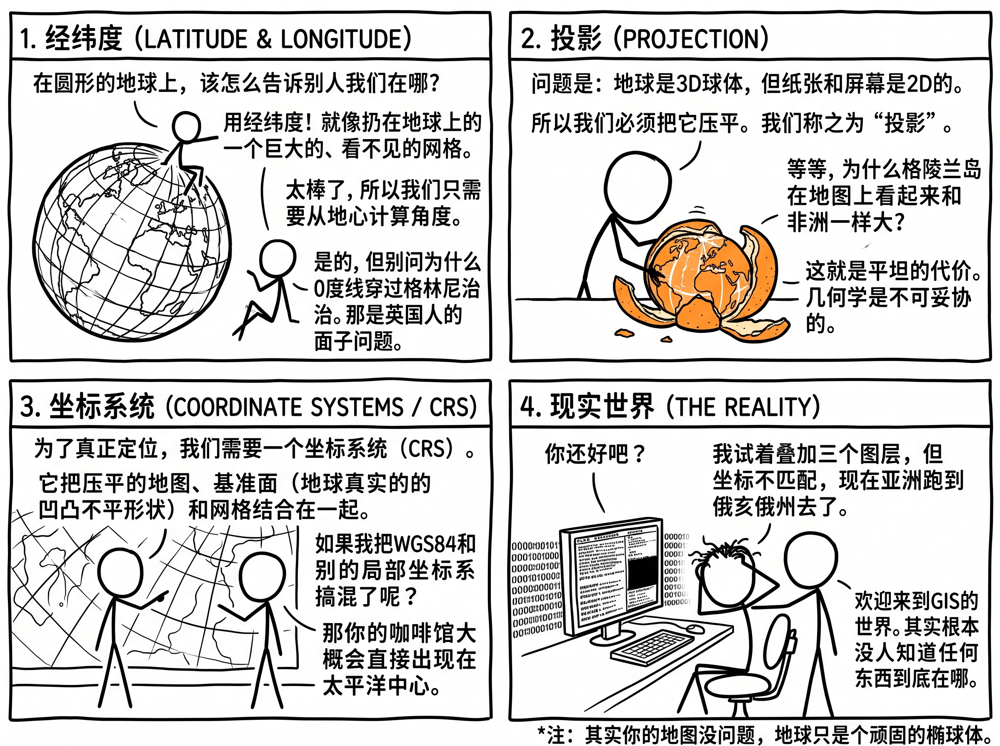

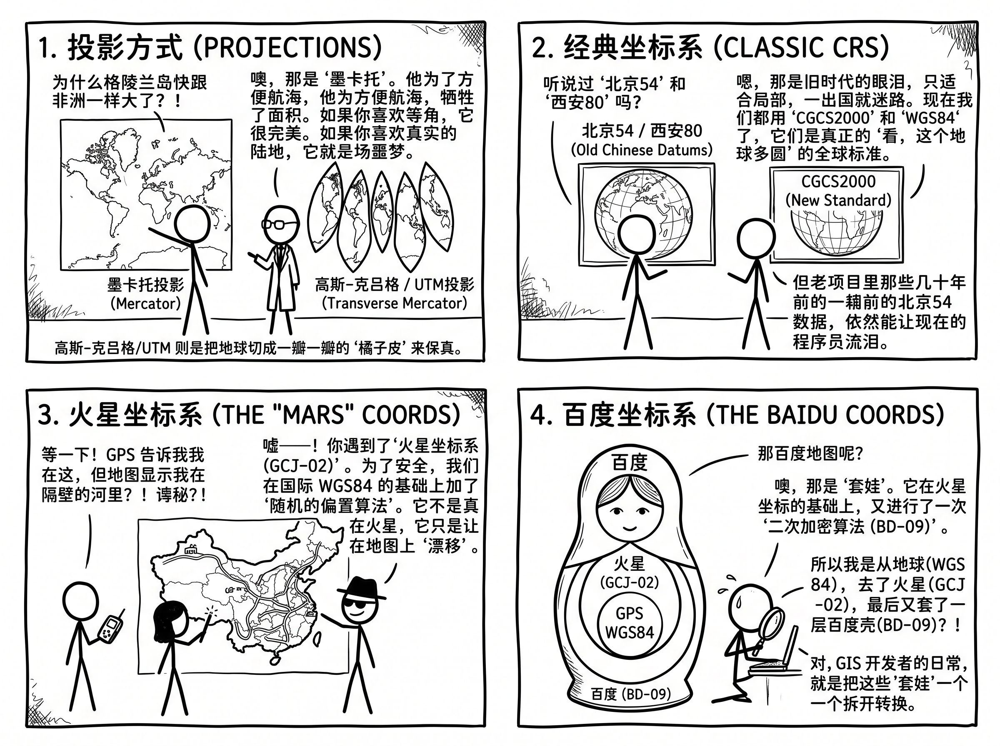

本数据中的`longitude_grid`与`latitude_grid`是**GCJ-02（火星坐标）的0.02°网格中心**。`points_from_xy(x, y)`中x放经度、y放纬度。GCJ-02不是EPSG:4326，下面先保留原始数值且不伪设EPSG编号。

In [ ]:
# GCJ-02没有可直接套用的EPSG编号；先保留原始几何，不随意设置4326。
import geopandas as gpd
located = posts.loc[posts['coordinate_valid']].copy()
geo = gpd.GeoDataFrame(located,
    geometry=gpd.points_from_xy(located['longitude_grid'], located['latitude_grid']))
geo[['city', 'longitude_grid', 'latitude_grid', 'geometry']].head()

In [ ]:
geo.crs

<a id="section-2-1"></a>
### 2.1 矢量与栅格：两种空间数据模型 **[重点]**

同一个空间现象可以用不同的数据模型表达。先判断“对象在哪里、边界是什么”，还是“每个像元记录什么值”，再选择工具。

| 比较 | 矢量（Vector） | 栅格（Raster） |
| --- | --- | --- |
| 组织方式 | 一行一个要素，几何为点、线、面，另有属性列 | 规则排列的行、列与像元值，可有多个波段 |
| 例子 | 微博位置点、道路折线、市与区县边界 | 卫星影像、地表温度、海拔、按规则格子排列的记录数 |
| 常见文件 | GeoJSON、GeoPackage（.gpkg）、Shapefile（通常由多个文件组成） | GeoTIFF（.tif）；气象变量也常用NetCDF（.nc）保存 |
| 主要工具 | GeoPandas处理表和几何，Shapely进行几何运算 | Rasterio读取地理栅格，Xarray处理带坐标和维度的数组 |

**规则的方格也可以是矢量。** 后面的`cells`每行保存一个多边形，仍是矢量数据；只有把格子值组织成完整的行列数组，并说明空间定位、分辨率与缺失值含义，才具备栅格数据的基本表达。我们已有的Parquet表保存的是坐标字段，也需要先构造`geometry`才能作为GeoDataFrame进行空间操作。

栅格分辨率决定像元覆盖范围，多波段可以表达RGB颜色或不同变量。**NoData表示未知或无有效观测，不能直接当作0。** 网页底图虽然常由图片瓦片组成，图片颜色也不等于可以直接分析的温度数值。

本节主要使用GeoPandas操作矢量；3.1.1用已有记录数生成一个栅格数组，观察同一信息的另一种表示。

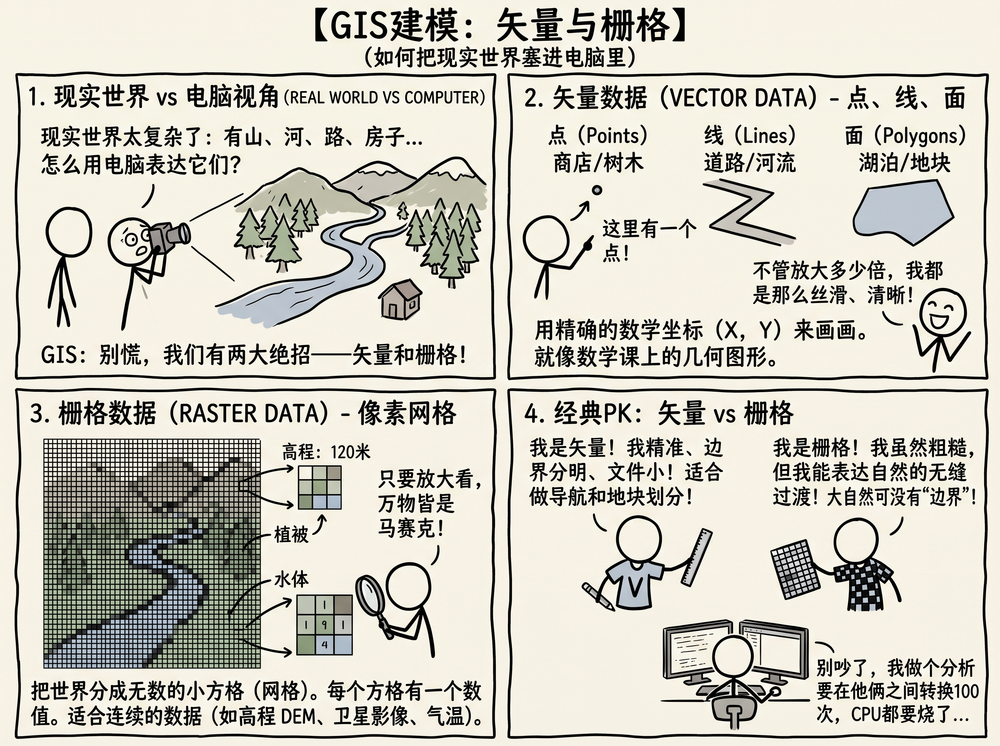

<a id="section-2-2"></a>
### 2.2 经纬度与米：先投影，再测量

经纬度单位是“度”，不能把`buffer(3000)`直接解释为3000米。`set_crs()`只声明坐标含义；`to_crs()`依据已知CRS重投影，两者都不会自动解决GCJ-02偏移。

先取成都记录，用`gcj2wgs()`近似换算原始数值，再将换算后的点声明为WGS84（EPSG:4326），最后投影到米制UTM 48N（EPSG:32648）。保留`longitude_grid`与`latitude_grid`原值供网格统计，不回写数据文件。该本地投影适用于成都附近；网格化和近似转换的误差仍然存在。

In [ ]:
# 原始city_geo保留GCJ-02坐标；另建city_wgs用于度量。
city_geo = geo.loc[geo['city_code'].eq('5101')].copy()
from xyconvert import gcj2wgs
city_xy_wgs = gcj2wgs(city_geo[['longitude_grid', 'latitude_grid']].to_numpy())
city_wgs = gpd.GeoDataFrame(city_geo.drop(columns='geometry'),
    geometry=gpd.points_from_xy(city_xy_wgs[:, 0], city_xy_wgs[:, 1]), crs='EPSG:4326')
city_m = city_wgs.to_crs('EPSG:32648')
# 原列仍是GCJ-02；米制坐标来自近似WGS84副本，两者不要混用。
pd.DataFrame({'GCJ-02经度': city_geo['longitude_grid'].head(),
              '近似WGS84经度': city_wgs.geometry.x.head(),
              '东向坐标（米）': city_m.geometry.x.head(),
              '北向坐标（米）': city_m.geometry.y.head()})

<a id="section-2-3"></a>
### 2.3 省、市、区县：行政边界怎样读取？ **[重点]**

行政边界是多边形范围，底图瓦片是背景图片，两者用途不同。随资料缓存四川省界、市州界与成都区县界，不要求每位同学实时下载。

`adcode`是六位行政代码；四川为510000，成都为510100。此处DataV.GeoAtlas边界来自高德，使用GCJ-02，与微博原网格可直接叠加。GeoJSON读取器可能默认赋EPSG:4326，我们清除这个不适用的标签，保留原坐标值。边界为教学参考快照，并非逐日重建的2022年边界。

In [ ]:
# 数据目录与微博Parquet保持同一种相对路径风格。
BOUNDARY_DIR = TUTORIAL_DIR / 'data/spatial/boundaries'
province_boundary = gpd.read_file(BOUNDARY_DIR / 'sichuan_province_gcj02.geojson').set_crs(None, allow_override=True)
# 只保留绘图字段，避免接口中的嵌套元数据影响JSON显示。
province_boundary = province_boundary[['adcode', 'name', 'geometry']].copy()
# 部分在线边界有自相交；修复拓扑，坐标体系仍为GCJ-02。
province_boundary.geometry = province_boundary.geometry.make_valid(method='structure', keep_collapsed=False)
city_boundaries = gpd.read_file(BOUNDARY_DIR / 'sichuan_cities_gcj02.geojson').set_crs(None, allow_override=True)
city_boundaries = city_boundaries[['adcode', 'name', 'geometry']].copy()
city_boundaries.geometry = city_boundaries.geometry.make_valid(method='structure', keep_collapsed=False)
city_boundaries.head(2)

**用GeoPandas绘制静态地图。** `plot()`使用Matplotlib生成图片，直接嵌入Notebook，适合课堂查看与报告。下面按市州名称分类配色；后面继续用同一种方法画网格和分级设色图。

本节静态地图采用轻微的XKCD手绘风格，与漫画配合阅读，并保留中文字体和清晰图例。样式只影响显示，不改变数据、几何坐标与分级阈值。行政轮廓来自缓存边界，静态图可离线查看；3.3另提供Plotly交互地图，用于缩放和悬停。

原始显示几何仍为GCJ-02，图形不能用于直接量取米制距离或面积。[GeoPandas静态绘图](https://geopandas.org/en/stable/docs/user_guide/mapping.html)、[Matplotlib XKCD样式](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xkcd.html)。

In [ ]:
# 第一次画静态地图时才导入Matplotlib；空间要素由GeoPandas.plot绘制。
import matplotlib.pyplot as plt
plt.xkcd(scale=0.5)  # 轻微手绘线条；只改变显示样式，不改变统计值和几何坐标。
# 手绘风格默认使用英文字体，改回跨平台中文字体列表。
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [
    'Microsoft YaHei', 'PingFang SC', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['font.size'] = 11
plt.rcParams['axes.unicode_minus'] = False


In [ ]:
# 静态图：按市州名称分类，离散色板用于区分行政区。
city_palette = plt.get_cmap('tab20').resampled(city_boundaries['name'].nunique())

fig, ax = plt.subplots(figsize=(10, 7))
city_boundaries.plot(ax=ax, column='name', categorical=True, cmap=city_palette,
    edgecolor='#555555', linewidth=0.5, alpha=0.2, legend=True,
    legend_kwds={'title': '市州', 'loc': 'upper left', 'bbox_to_anchor': (1, 1), 'fontsize': 8})
# 同一个ax上加省界，只画边线；不把GCJ-02误标为WGS84。
province_boundary.boundary.plot(ax=ax, color='#163d59', linewidth=1.2)
ax.set_title('四川市州：分类配色（静态图）')
ax.set_axis_off()  # 隐藏坐标轴，不把角度坐标误读为米制距离。
plt.show()  # 输出一张可直接保存、放入报告的静态图。


<a id="section-2-4"></a>
### 2.4 成都区县：换一个行政层级 **[重点]**

In [ ]:
# 读取成都区县面；区县边界不改变微博0.02度的位置分辨率。
district_boundaries = gpd.read_file(BOUNDARY_DIR / 'chengdu_districts_gcj02.geojson').set_crs(None, allow_override=True)
district_boundaries.geometry = district_boundaries.geometry.make_valid(method='structure', keep_collapsed=False)


In [ ]:
district_boundaries.head(2)

In [ ]:
# 静态图：复用刚读取的成都区县面；名称配色不表示数量高低。
district_palette = plt.get_cmap('tab20').resampled(district_boundaries['name'].nunique())
fig, ax = plt.subplots(figsize=(10, 7))
district_boundaries.plot(ax=ax, column='name', categorical=True, cmap=district_palette,
    edgecolor='#555555', linewidth=0.5, alpha=0.15, legend=True,
    legend_kwds={'title': '区县', 'loc': 'upper left', 'bbox_to_anchor': (1, 1), 'fontsize': 8})
ax.set_title('成都区县：分类配色（静态图）')
ax.set_axis_off()
plt.show()


[DataV.GeoAtlas数据与使用说明](https://datav.aliyun.com/portal/school/atlas/atlas_aigc)；来源、坐标与缓存时间见`data/spatial/boundaries/provenance.json`。边界只用于教学对照，源记录的城市字段不在这里重新赋值。

<a id="section-3"></a>
## 3 网格汇总：记录多与用户多是否一样？ **[重点]**

先按已有网格分组，不给0.02度网格赋予统一的平方公里面积。`size`数记录，`nunique`数不同用户。二者的差异能提示：大圆可能来自很多用户，也可能被少数高频用户放大。

先画有坐标轴的网格散点，悬停查看记录数与用户数。它不加载任何在线底图，也不提供行政边界。

In [ ]:
# 一行一个成都观测网格，避免把全部重复记录逐点画上去。
grids = city_geo.groupby(['longitude_grid', 'latitude_grid']).agg(
    n_posts=('post_id', 'size'), n_users=('user_id', 'nunique')).reset_index()
grids.sort_values('n_posts', ascending=False).head()

In [ ]:
# 第一次画图时再导入Plotly；图形可以缩放、悬停和开关图例。
import plotly.express as px
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook'
px.defaults.template = 'simple_white'

In [ ]:
# 大小编码记录数，颜色编码用户数；悬停比较两个分母。
fig = px.scatter(grids, x='longitude_grid', y='latitude_grid',
    size='n_posts', color='n_users', hover_data=['n_posts', 'n_users'],
    labels={'longitude_grid': '经度', 'latitude_grid': '纬度',
            'n_posts': '记录数', 'n_users': '用户数'},
    title='成都观测网格：记录数与用户数（无底图）')
fig

<a id="section-3-1"></a>
### 3.1 把网格画成面：空间分辨率 **[重点]**

一个点只标出网格中心，不能显示它覆盖多大范围。数据以0.02度为间隔保存中心，我们按“中心±0.01度”重建显示格子；没有原始精确位置，不能恢复每条记录在格内哪里。

**空间分辨率**指我们区分空间细节的尺度。0.02度网格只把位置分到这个量级，放大地图不会变出街道级精度。经度1度的米数随纬度变化，所以0.02度不等于固定的2公里，两个方向也不同。

`shapely.box(左, 下, 右, 上)`一次生成一组矩形面；颜色表示每个格子的记录数，不把每条微博随机撒成新的位置点。没有观测的格子没有画出，不能据此判定那里没有人。

In [ ]:
# 在需要网格面时导入Shapely；使用已有网格中心，避免对隐去的精确位置作猜测。
import shapely
CELL_DEG = 0.02
half = CELL_DEG / 2
cells = gpd.GeoDataFrame(grids.copy(), geometry=shapely.box(
    grids['longitude_grid']-half, grids['latitude_grid']-half,
    grids['longitude_grid']+half, grids['latitude_grid']+half), crs=None)
# 将整格边界近似转换后再投影估面积，不能直接对GCJ-02做to_crs。
cells_wgs = cells.copy()
cells_wgs.geometry = shapely.transform(cells.geometry.array, gcj2wgs)
cells_wgs = cells_wgs.set_crs('EPSG:4326')
cells['area_km2'] = cells_wgs.to_crs('EPSG:32648').area / 1_000_000
cells[['n_posts', 'n_users', 'area_km2']].head()

**坐标处理遵循“原坐标显示、转换后测量”。** 微博网格与DataV边界都是GCJ-02，直接叠加高德底图，不重复调用`wgs2gcj`。GCJ-02没有这里可直接使用的EPSG编号，原始显示几何的CRS留空，不能通过`set_crs(4326)`把它变成WGS84。

需要测量时，先用`gcj2wgs`近似转换GCJ-02数值，再声明EPSG:4326，最后投影到成都附近适用的EPSG:32648。近似转换和0.02°网格化都限制精度；它们不会恢复真实位置。原始显示几何的CRS留空，是这里明确保留GCJ-02坐标的约定。

In [ ]:
# 保留原始GCJ-02网格作为显示副本，不重复做坐标偏移。
map_cells = cells.copy()
# 静态图：同一批0.02度矢量网格，仍用连续色带表示记录数。
fig, ax = plt.subplots(figsize=(9, 7))
map_cells.plot(ax=ax, column='n_posts', cmap='YlOrRd',
    edgecolor='#555555', linewidth=0.3, alpha=0.65, legend=True,
    legend_kwds={'label': '网格内记录数', 'shrink': 0.7})
# 叠加成都轮廓，帮助辨认城市范围。
city_boundaries.loc[city_boundaries['adcode'].eq(510100)].boundary.plot(
    ax=ax, color='#163d59', linewidth=1.2)
ax.set_title('成都0.02°网格：记录数（静态图）')
ax.set_axis_off()
plt.show()


<a id="section-3-1-1"></a>
#### 3.1.1 同一组格子，改成栅格数组 **[扩展]**

刚才的`cells`是“一行一个面”；现在把同一批`grids`的记录数放入“行=纬度格号、列=经度格号”的二维数组。整数格号避免浮点数索引误差，`reindex()`补齐两个观测位置之间缺少的行列，防止把相隔很远的格子挤到一起。

未观测格子保留`NaN`，作为本例的NoData；不补0。行从北到南排列，经纬度标在**像元中心**，空间分辨率仍为0.02°，不是统一的米制距离。

In [ ]:
# 将网格中心转换成整数格号；round消除浮点数计算带来的微小误差。
raster_source = grids.assign(
    ix=(grids['longitude_grid'] / CELL_DEG).round().astype(int),
    iy=(grids['latitude_grid'] / CELL_DEG).round().astype(int))
# pivot把一行一格的表变成二维矩阵，每个值仍是该格内的记录数。
count_raster = raster_source.pivot(index='iy', columns='ix', values='n_posts')
# 补齐完整矩形范围；纬度从大到小排列，使第一行位于北侧。
count_raster = count_raster.reindex(
    index=range(raster_source['iy'].max(), raster_source['iy'].min() - 1, -1),
    columns=range(raster_source['ix'].min(), raster_source['ix'].max() + 1))
print('数组行、列：', count_raster.shape, '有观测的像元：', count_raster.count().sum())
count_raster.iloc[:5, :5]  # 西北角可能没有观测，因此会显示NaN。


In [ ]:
# imshow直接绘制二维数值数组；这是坐标轴图，不依赖在线底图。
fig = px.imshow(count_raster.to_numpy(),
    x=(count_raster.columns * CELL_DEG).round(2),
    y=(count_raster.index * CELL_DEG).round(2),
    origin='upper', color_continuous_scale='YlOrRd',
    labels={'x': 'GCJ-02经度', 'y': 'GCJ-02纬度', 'color': '记录数'},
    title='相同的0.02°记录数：栅格数组表示（空白为NoData）')
# 按实际纬度向上递增，保证北在上；覆盖imshow默认的图像行号方向。
fig.update_yaxes(autorange=True)
fig


数组只是数值部分，完整地理栅格还要保存坐标体系、像元分辨率、空间范围和NoData等信息。本例复用GCJ-02格子，不把它直接标为EPSG:4326，也不额外导出GeoTIFF；GeoPandas负责矢量操作，不能用`read_file()`替代栅格读取。

如果以后叠加WGS84气象栅格与GCJ-02微博位置，需要先统一坐标体系，再决定按点提取像元值还是按区域统计；仅把两张图叠在一起不等于完成数据匹配。

<a id="section-3-2"></a>
### 3.2 改成0.04度：哪些细节消失了？ **[重点]**

把相邻2×2个细格合成0.04度粗格，观察局部高值怎样合并。格子边长约变为2倍，面积约变为4倍；单格数量通常会增加，不能把变深的颜色直接解读为“活动变强”。

粗格边界从同一条细格边界−0.01度开始，保证只是合并，不改变原格子的对齐方式。统计直接回到原始成都记录：记录数可以相加，用户数必须重新去重，不能相加细格用户数。

In [ ]:
# floor向下取整，确定每条记录落入哪个粗格；此时才引入NumPy。
import numpy as np
COARSE_DEG = 0.04
coarse_source = city_geo.assign(
    ix=np.floor((city_geo['longitude_grid']+half)/COARSE_DEG).astype(int),
    iy=np.floor((city_geo['latitude_grid']+half)/COARSE_DEG).astype(int))
coarse = coarse_source.groupby(['ix', 'iy']).agg(
    n_posts=('post_id', 'size'), n_users=('user_id', 'nunique')).reset_index()
# ix、iy是格子编号；乘分辨率并减half得到与细格对齐的左、下边界。
left = coarse['ix']*COARSE_DEG-half
bottom = coarse['iy']*COARSE_DEG-half
coarse_cells = gpd.GeoDataFrame(coarse, geometry=shapely.box(
    left, bottom, left+COARSE_DEG, bottom+COARSE_DEG), crs=geo.crs)
# 检查两个尺度的记录总数守恒，而不是把绘图差异误当成新记录。
pd.DataFrame({'分辨率（度）': [CELL_DEG, COARSE_DEG],
    '有观测的格子数': [len(cells), len(coarse_cells)],
    '记录总数': [cells['n_posts'].sum(), coarse_cells['n_posts'].sum()]})

In [ ]:
# 保留相同坐标体系的粗网格副本。
coarse_display = coarse_cells.copy()
# 静态图：更换为相同的0.04度粗网格，指标仍是记录数。
fig, ax = plt.subplots(figsize=(9, 7))
coarse_display.plot(ax=ax, column='n_posts', cmap='YlOrRd',
    edgecolor='#555555', linewidth=0.4, alpha=0.65, legend=True,
    legend_kwds={'label': '网格内记录数', 'shrink': 0.7})
ax.set_title('成都0.04°网格：记录数（静态图）')
ax.set_axis_off()
plt.show()


读图时比较格子边界、图例数值与前面的网格统计表，不能只比较两幅图的颜色深浅；默认连续图例按各自数据范围缩放。想比较单位面积强度，还需要在合适投影下计算各格面积，明确采用“每平方公里记录数”，并保持相同色标。

<a id="section-3-3"></a>
### 3.3 Plotly也可以更换高德底图 **[扩展]**

Plotly的`choropleth_map`绘制面，`scatter_map`绘制点。`map_layers`可添加自定义栅格瓦片；`below='traces'`把底图放到数据下面。这里设置高德瓦片地址，并复用前面的GCJ-02显示副本，无需改用高德JS API。

需要缩放、悬停查看网格属性时，可运行下面的Plotly交互地图；指标与前面的静态细网格图相同。[Plotly自定义瓦片说明](https://plotly.com/python/tile-map-layers/)

In [ ]:
# 需要交互地图时才设置高德瓦片地址；底图加载需要联网。
AMAP_TILE_URL = 'https://wprd01.is.autonavi.com/appmaptile?lang=zh_cn&size=1&scale=1&style=7&x={x}&y={y}&z={z}'
# GeoDataFrame的索引对应GeoJSON要素id，locations据此匹配每个格子。
fig = px.choropleth_map(map_cells, geojson=map_cells.__geo_interface__,
    locations=map_cells.index.astype(str), color='n_posts', color_continuous_scale='YlOrRd',
    hover_data=['n_users'], center={'lon': 104.07, 'lat': 30.67}, zoom=9, opacity=0.65,
    map_style='white-bg', title='Plotly：高德底图与0.02度网格（GCJ-02粗网格）')
# below缺省时不透明瓦片可能盖住格子，所以明确放到traces下面。
fig.update_layout(map_layers=[{'sourcetype': 'raster', 'source': [AMAP_TILE_URL],
    'sourceattribution': '高德地图', 'below': 'traces'}], margin={'l': 0, 'r': 0, 'b': 0, 't': 50})
fig

<a id="section-4"></a>
## 4 回到同一用户：位置和时段 **[重点]**

空间图中的点属于谁、什么时候出现？先在四川样本中选择至少5条记录、至少2个观测日期的用户，再看时空分布。这个门槛只是课堂筛选条件，不能当作平台的“活跃用户”定义。

选一位有多个观测网格、5—20条记录的用户作为案例，按北京时间排序，再用Plotly在高德底图上绘制点与连线。**点的颜色表示观测序号，线按表中的先后顺序连接观测位置**；悬停查看序号、时间与城市。将`mode='markers+lines'`改为`mode='markers'`即可只显示点。

连线用于辅助阅读观测顺序，不表示实际行走路线；相邻记录之间可能间隔几分钟，也可能间隔几天，无法据此推断速度或停留时间。同一时刻的记录不能确定先后。位置仍是0.02°网格中心，相同网格上的点可能重叠；案例也不代表典型用户。

In [ ]:
# 在一张表中检查用户记录数、日期数与不同观测网格数。
profiles = geo.groupby('user_id').agg(n_posts=('post_id', 'size'),
    active_days=('date', 'nunique'), n_grids=('geometry', 'nunique'))
eligible = profiles.loc[profiles['n_posts'].ge(5) & profiles['active_days'].ge(2)]
# 选择记录量适中、位置有变化的一位案例；不把ID作为图例或标题。
candidates = eligible.loc[eligible['n_posts'].le(20) & eligible['n_grids'].ge(2)]
case_id = candidates.sort_values(['n_grids', 'n_posts'], ascending=False).index[0]
case = geo.loc[geo['user_id'].eq(case_id)].sort_values('created_at', kind='stable').copy()
case['period'] = case['hour'].lt(12).map({True: '00—11点', False: '12—23点'})
# 序号只表示记录顺序；多个记录也可能对应同一个观测时刻。
case['序号'] = range(1, len(case) + 1)
print('合格用户数：', len(eligible), '案例记录数：', len(case))
case.head(2)

In [ ]:
case.user_id.nunique(),case.shape[0]

In [ ]:
import plotly.graph_objects as go  # 使用普通Figure绘图，无需控件或回调。

# case已按时间排序；连线依次连接表中的记录，不自动计算实际道路。
case_map = go.Figure(go.Scattermap(
    lon=case['longitude_grid'].tolist(), lat=case['latitude_grid'].tolist(),
    mode='markers+lines',  # 改成'markers'可只看位置点。
    line={'width': 2, 'color': '#64748b'},
    marker={'size': 12, 'color': case['序号'].tolist(), 'colorscale': 'Viridis',
            'showscale': True, 'colorbar': {'title': '观测序号'}},
    # text保存每个点的悬停信息；时间使用北京时间。
    text=('第' + case['序号'].astype(str) + '条 · '
          + case['created_at'].dt.strftime('%m-%d %H:%M:%S')
          + ' · ' + case['city'].fillna('未知城市')).tolist(),
    hovertemplate='%{text}<br>经度：%{lon:.2f}<br>纬度：%{lat:.2f}<extra></extra>'))

# 使用3.3节的高德瓦片地址，放在点线下方并调淡；底图加载需要联网。
# 数据是GCJ-02网格中心，与高德底图保持一致，不在这里转换坐标。
case_map.update_layout(
    map={'style': 'white-bg', 'zoom': 10,
         'center': {'lon': case['longitude_grid'].mean(), 'lat': case['latitude_grid'].mean()},
         'layers': [{'sourcetype': 'raster', 'source': [AMAP_TILE_URL],
                     'sourceattribution': '高德地图', 'below': 'traces', 'opacity': 0.35}]},
    title='一个用户的位置观测与先后顺序（连线非实际路线）',
    height=520, autosize=True, margin={'l': 0, 'r': 0, 'b': 0, 't': 55})
case_map


<a id="section-4-1"></a>
### 4.1 网格×时段表：每个时段分别归一化

交叉表的行是网格，列是时段。每列除以该时段记录总数，才能比较“同一用户在两个时段的记录分布”。它描述记录分布，不是一天中停留时间的分配。

In [ ]:
# crosstab建立计数表；div沿列对齐分母，每个非空时段合计为1。
counts = pd.crosstab([case['longitude_grid'], case['latitude_grid']], case['period'])
period_share = counts.div(counts.sum(axis=0), axis=1)
period_share

<a id="section-5"></a>
## 5 空间连接：位置记录属于哪个范围？ **[重点]**

空间连接（Spatial join）按两个空间对象之间的几何关系连接属性，例如“给每条位置记录附上所在区县”。它保留要素几何，通常不切割面；几何叠置（Overlay）则会生成交集、差集等新形状。这里先学连接，再用一个可选示例比较两者。

| 操作 | 匹配依据 | 本节例子 |
| --- | --- | --- |
| `merge()`属性连接 | 共有字段的值 | 用行政代码连接城市名称 |
| `sjoin()`空间连接 | 点、线、面的空间关系 | 判断位置点是否落在区县或分析圆内 |
| `overlay()`几何叠置 | 几何交集、并集、差集等 | 把跨越城市边界的格子切出城内部分 |

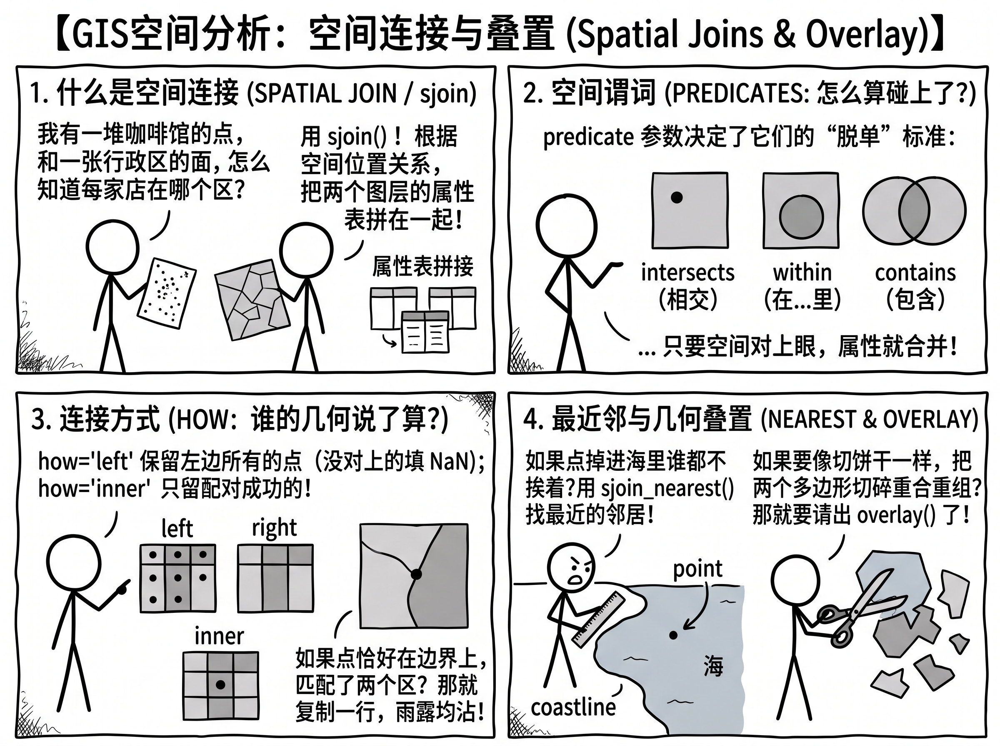

<a id="section-5-1"></a>
### 5.1 先选关系，再选保留哪些记录 **[重点]**

`left.sjoin(right, how=..., predicate=...)`的左表在前、右表在后。使用前要确认两表坐标体系一致、几何有效；相同的`crs`标签只是检查的一部分。本课原始微博点与高德边界都为GCJ-02，CRS都留空是已知坐标约定，不能据此推断任意两份`crs=None`的数据都可直接连接。

| `predicate` | 左表为点、右表为面时的含义 | 点恰好在面边界上 |
| --- | --- | --- |
| `within` | 点在面内部 | 不匹配 |
| `covered_by` | 点被面覆盖，允许落在边界上 | 匹配 |
| `intersects` | 两个几何有公共部分 | 匹配 |

`contains`与`within`方向相反：面包含点，可以写成“面表连接点表，`predicate='contains'`”。

`how='left'`保留所有左表要素，未匹配的右表字段为缺失值；`how='inner'`只保留匹配对。**两者都可能把一条记录展开成多行**：点可能同时匹配多个重叠的面，边界点也可能匹配两个相邻面。

<a id="section-5-2"></a>
### 5.2 给成都位置记录连接区县，再汇总 **[重点]**

输入左表是成都位置记录`city_geo`，右表是区县边界。输出仍保留左表的点几何，并增加区县名称和代码。先用`left`保留全部记录，才能检查哪些没有匹配；原来的`city`字段保持不变。

这里按**网格中心落在哪个区县**来归属，并非确定真实发帖位置所属区县。跨界网格可能覆盖多个区县；行政边界也是教学快照。因此保留未匹配记录，不把它们自动认定为错误，也不强行分给最近区县。

In [ ]:
# 只取连接需要的属性，并给右表字段加清楚的名称，避免与原字段混淆。
district_lookup = district_boundaries[['adcode', 'name', 'geometry']].rename(
    columns={'adcode': 'district_code', 'name': 'district_name'})
# 先预览区县代码、名称和几何，再在下一格执行空间连接。
district_lookup.head()

In [ ]:
# within用网格中心匹配区县内部；输出点仍来自city_geo。
district_posts = city_geo.sjoin(district_lookup, how='left', predicate='within')
print('原记录数：', len(city_geo), '连接后行数：', len(district_posts))
print('未匹配记录数：', district_posts.loc[district_posts['index_right'].isna(), 'post_id'].nunique())
# 一条帖子匹配多个面时会产生多行，不能只看连接后的总行数。
print('匹配到多个区县的记录数：', district_posts.groupby('post_id')['index_right'].count().gt(1).sum())
district_posts.head(3)


In [ ]:
# 按区县代码和名称汇总已匹配记录，保留后续连接键；nunique按ID去重，不把一条帖子重复计数。
district_summary = district_posts.dropna(subset=['district_code']).groupby(['district_code', 'district_name']).agg(
    n_posts=('post_id', 'nunique'), n_users=('user_id', 'nunique'))
district_summary.sort_values('n_posts', ascending=False)


同一用户可能出现在多个区县，因此各区县用户数不能相加当作全市用户数。如果记录匹配了多个面，即使每个区县内部去重，也可能在跨区县合计时重复计入，必须先检查边界重叠与分析口径。

没有匹配记录的区县不会出现在上表中；要显示全部区县，可从边界表出发按区县代码做属性连接。本例主要学习空间匹配与统计，不据此给区县排“真实人气”名次。

<a id="section-5-2-1"></a>
#### 5.2.1 分级设色：把区县统计画回地图 **[重点]**

刚才得到了各区县的记录数与用户数。现在把统计表按行政代码连接回区县面，完成“**空间连接 → 分组统计 → 属性连接 → 地图表达**”的流程。

**分级设色地图（Classified choropleth）**把面要素的数值划为几个区间，同一区间使用同一种颜色。它与前面的连续色带不同：连续色带随数值渐变，分级设色则让读者根据图例读取所在等级。区县名称的分类配色只用于区分名称，也不等于按数值分级。

| 分级方法 | 如何划分 | 读图时注意什么 |
| --- | --- | --- |
| 等距 `EqualInterval` | 将最小值到最大值之间的范围等分 | 极端高值可能使多数区县挤在低等级 |
| 分位数 `Quantiles` | 尽量让每级包含相近数量的区县 | 每级数值跨度不同；重复值可能使数量不相等或级数减少 |
| 自定义 `UserDefined` | 指定每一级的数值上限 | 阈值要有说明，适合固定规则后跨日期比较 |
| 自然断点 `NaturalBreaks` **[扩展]** | 根据数值分布寻找组内差异较小的分组 | 自动阈值依赖本批数据，不保证不同地图可直接比较 |

下面以**样本中各区县的不同用户数**为指标，用浅到深的顺序色带表示由低到高。它是采集样本量，不是区县人口、用户密度或平台渗透率。

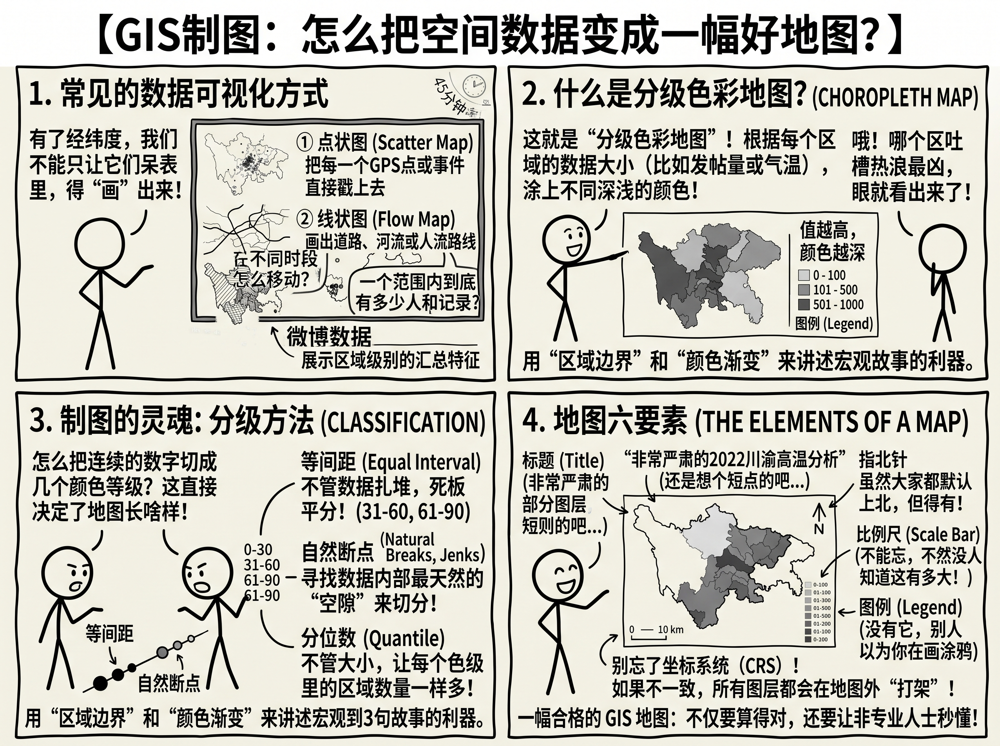

In [ ]:
# reset_index把分组键变回普通列，方便按行政代码连接。
district_values = district_summary.reset_index()
# 从边界表出发做left连接，保留全部区县；代码是连接键，名称用于显示。
district_choropleth = district_lookup.merge(
    district_values[['district_code', 'n_posts', 'n_users']],
    on='district_code', how='left', validate='one_to_one')
# 未匹配的统计值保留NaN，不能直接解释为无人或没有发帖。
district_choropleth[['district_name', 'n_posts', 'n_users']]


In [ ]:
district_choropleth.head()

`plot()`把区县面画到Matplotlib坐标轴`ax`上，图例直接保存在静态图片中。

- `column='n_users'`指定用户数；改成`'n_posts'`可观察记录数。
- `scheme='Quantiles'`选择分位数，`k=4`请求四级；改成`'EqualInterval'`可观察等距分级。
- `cmap='YlOrRd'`使用黄—橙—红顺序色带，颜色越深表示数值等级越高。
- `legend=True`显示图例，`legend_kwds`中的`title`设置标题、`interval=True`显示开闭区间；`missing_kwds`将缺失值标为灰色。

分类由课程环境已有的`mapclassify`完成，无需另外导入。

In [ ]:
# 静态分级图：复用同一张区县表、用户数指标、分位数规则与四级色带。
fig, ax = plt.subplots(figsize=(9, 7))
district_choropleth.plot(ax=ax, column='n_users', scheme='Quantiles', k=4,
    cmap='YlOrRd', edgecolor='#555555', linewidth=0.6, alpha=0.7, legend=True,
    missing_kwds={'color': '#d9d9d9', 'label': '无匹配观测'},
    legend_kwds={'title': '区县样本用户数', 'fmt': '{:.1f}', 'interval': True,
                 'loc': 'upper left', 'bbox_to_anchor': (1, 1)})
# title设置分级图例的标题；区间与色块一起解释数值范围。
ax.set_title('区县样本用户数：分位数四级（静态图）')
ax.set_axis_off()
plt.show()


**同一份数据，换成固定阈值。** 下面用500、1500、3000、10000作为四级上限；区间依次为“不超过500”“大于500且不超过1500”等。阈值只用于教学对照，不代表正式的活跃度等级；最大上限需要覆盖本例全部有效值。

`classification_kwds={'bins': ...}`向`UserDefined`传入上限列表，这时按列表分级，无需再指定`k`。读两幅地图时，对照具体区间和区县统计表，观察颜色变化来自哪里。

In [ ]:
# 四级上限沿用同一套规则，最大上限需要覆盖全部有效值。
USER_BINS = [500, 1500, 3000, 10000]
# 静态分级图：直接复用USER_BINS，按相同的固定上限划分等级。
fig, ax = plt.subplots(figsize=(9, 7))
district_choropleth.plot(ax=ax, column='n_users', scheme='UserDefined',
    classification_kwds={'bins': USER_BINS}, cmap='YlOrRd',
    edgecolor='#555555', linewidth=0.6, alpha=0.7, legend=True,
    missing_kwds={'color': '#d9d9d9', 'label': '无匹配观测'},
    legend_kwds={'title': '区县样本用户数', 'fmt': '{:.0f}', 'interval': True,
                 'loc': 'upper left', 'bbox_to_anchor': (1, 1)})
ax.set_title('区县样本用户数：固定阈值（静态图）')
ax.set_axis_off()
plt.show()


读图时先回答三个问题：画的是什么指标？用什么规则分级？缺失值如何表达？

**比较不同日期或区域时，需要固定指标定义、分级阈值和颜色对应关系。** 每张图分别计算分位数或自然断点，同样的深红色可能对应不同用户数。使用固定上限之前，也要确认它们覆盖要比较的全部数据。

区县大小不一，记录数与用户数也受采样覆盖影响。要讨论“密度”，需另外计算合适的面积或人口分母；要讨论“每用户记录数”，则用记录数除以用户数。这些指标的单位与含义不同，不能混用同一套数值阈值。灰色的无匹配观测与有效计数0也应分开表达。

[GeoPandas静态地图与分级设色](https://geopandas.org/en/stable/docs/user_guide/mapping.html)。

<a id="section-5-3"></a>
### 5.3 缓冲区与空间连接：3公里内有哪些记录？ **[重点]**

缓冲区是在指定距离内构造的面，接下来继续用同一种`sjoin()`操作查询范围内记录。这里以**成都记录的坐标中位位置**为教学参考点，构造3公里分析圆；它不是官方城市中心，也不代表避暑设施或真实服务范围。

这一次涉及距离，使用前面得到的米制`city_m`；缓冲区沿用相同CRS。`inner`只返回圆内匹配记录，`within`不包括圆周上的点。

In [ ]:
# Point在投影坐标下构造中心；buffer的单位与city_m一致，为米。
from shapely.geometry import Point
center = Point(city_m.geometry.x.median(), city_m.geometry.y.median())
RADIUS_M = 3000  # 首次做缓冲区时才设置距离。
zones = gpd.GeoDataFrame({'zone': ['观测中位点周边3km']},
                         geometry=[center.buffer(RADIUS_M)], crs=city_m.crs)
# within要求点在圆的内部；匹配结果仍是一行一条位置记录。
inside = city_m.sjoin(zones, how='inner', predicate='within')
print('圆内记录：', len(inside), '圆内用户：', inside['user_id'].nunique())
inside.groupby('date').agg(n_posts=('post_id', 'size'), n_users=('user_id', 'nunique'))

In [ ]:
# 坐标减去参考点，让图上0表示分析圆中心；只改变显示坐标。
xy = pd.DataFrame({'x': city_m.geometry.x-center.x, 'y': city_m.geometry.y-center.y})
xy = xy.groupby(['x', 'y']).size().rename('n_posts').reset_index()
fig = px.scatter(xy, x='x', y='y', size='n_posts', labels={'x': '相对参考点东向（米）',
    'y': '相对参考点北向（米）', 'n_posts': '记录数'}, title='3公里教学分析圆与观测网格')
# 明确设置线宽与透明填充，避免绘图主题将圆的边线隐藏。
fig.add_shape(type='circle', x0=-RADIUS_M, x1=RADIUS_M, y0=-RADIUS_M, y1=RADIUS_M,
              line_color='#e45756', line_width=2, fillcolor='rgba(0,0,0,0)', opacity=1)
# 只缩放显示到参考点附近，不改变上一格范围查询使用的数据。
fig.update_xaxes(range=[-15000, 15000])
fig.update_yaxes(range=[-15000, 15000], scaleanchor='x', scaleratio=1)
fig

<a id="section-5-4"></a>
### 5.4 空间连接与几何叠置有什么不同？ **[扩展]**

把同一批网格与成都行政边界进行比较：`sjoin(..., predicate='intersects')`找出与成都有交集的格子，保留整格几何；`overlay(..., how='intersection')`生成两者相交的部分，边缘格子会被切割。

两份输入都保留原始GCJ-02坐标，本例只做拓扑运算，不计算度数面积。

In [ ]:
# 取成都面，与已有矢量网格比较；不更改cells本身。
chengdu_boundary = city_boundaries.loc[city_boundaries['adcode'].eq(510100), ['name', 'geometry']]
matched_cells = cells.sjoin(chengdu_boundary, how='inner', predicate='intersects')
print('相交的完整网格数：', len(matched_cells))
matched_cells[['n_posts', 'name', 'geometry']].head()


In [ ]:
# 给原格子保留编号，便于比较切割前后的几何；cells本身不变。
cut_cells = cells.rename_axis('grid_id').reset_index().overlay(chengdu_boundary, how='intersection')
# 根据编号取回完整网格，geom_equals逐行判断形状是否相同。
original_shapes = cells.geometry.reindex(cut_cells['grid_id']).reset_index(drop=True)
cut_cells['geometry_changed'] = ~cut_cells.geometry.geom_equals(original_shapes)
print('相交部分的要素数：', len(cut_cells), '其中被切割的格子数：', cut_cells['geometry_changed'].sum())
# 只展示形状发生变化的边缘格子，避免前几行完整格子掩盖切割效果。
cut_cells.loc[cut_cells['geometry_changed'], ['grid_id', 'n_posts', 'name', 'geometry']].head()


**切了几何，不等于重新分配了记录。** `overlay()`会把原格子的`n_posts`属性带到切片上，但不知道每条记录在格内的真实位置，不能把这个值解释为切片内的真实记录数。按面积比例分摊也需要额外的均匀分布假设。本节区县统计采用5.2的网格中心归属口径。

操作说明：[GeoPandas空间连接](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html#spatial-joins)、[几何叠置](https://geopandas.org/en/stable/docs/user_guide/set_operations.html)；地理栅格读取可进一步了解[Rasterio基础](https://rasterio.readthedocs.io/en/stable/quickstart.html)。

<a id="section-6"></a>
## 6 综合练习与解释

<a id="section-6-1"></a>
### 6.1 改变分析范围 **[练习]**

将分析圆从3公里改为5公里，用空间连接重新计算记录数和用户数。只改距离，不要改样本。

<details><summary>展开参考思路与代码</summary><p>半径增大时，圆内记录应包含原来3公里圆内的记录；用户数不等于记录数。</p><pre><code class="language-python">larger_zone = gpd.GeoDataFrame({&#x27;zone&#x27;: [&#x27;5km&#x27;]}, geometry=[center.buffer(5000)], crs=city_m.crs)&#10;larger_inside = city_m.sjoin(larger_zone, predicate=&#x27;within&#x27;)&#10;larger_inside.agg({&#x27;post_id&#x27;: &#x27;size&#x27;, &#x27;user_id&#x27;: &#x27;nunique&#x27;})</code></pre></details>

<a id="section-6-2"></a>
### 6.2 找出重复记录较多的网格 **[练习]**

为grids增加每用户平均记录数，找出用户数至少5、平均记录数最高的前5个网格。

<details><summary>展开参考思路与代码</summary><p>分母是每个网格内的不同用户数。同一用户可能出现在多个网格，各网格用户数之和并非全市用户总数。</p><pre><code class="language-python">comparison = grids.assign(posts_per_user=grids[&#x27;n_posts&#x27;] / grids[&#x27;n_users&#x27;])&#10;comparison.loc[comparison[&#x27;n_users&#x27;].ge(5)].nlargest(5, &#x27;posts_per_user&#x27;)</code></pre></details>

<a id="section-6-3"></a>
### 6.3 开放问题：能称为通勤吗？ **[练习]**

如果案例在上午与下午出现于不同网格，能否认定用户通勤？写出至少两条需要补充的证据。

<details><summary>展开参考思路与代码</summary><p>先区分记录位置与真实位置；离散帖子无法给出完整路径、停留时间或出行目的。</p><pre><code class="language-python">conclusion = &#x27;只能描述同一用户的时段位置分布差异；还需要定位机制、坐标体系、跨日重复性和更多连续观测。&#x27;&#10;conclusion</code></pre></details>

下一节：[05 Heatwave and User Expression](05_heatwave_user_expression.ipynb)。先保留“记录、用户、网格、日期”的分析单位，再增加文本候选标签与气象背景。